# Statistical Analysis and Figure Export

Adds rigorous statistical testing to the height/width ratio analysis and exports
all figures to `paper/figures/` for use in the Quarto manuscript.

**Data source:** `artifacts.csv` — physical dimensions from the CDLI catalogue.
83,745 tablets have both height and width measurements (~88% of the 94,936-tablet
image corpus). This notebook uses physical dimensions in mm; the image-based
pixel ratios in notebook 2.1 are complementary but require the preprocessed
image pipeline to be run first.

## Tests performed
1. Log-scale box plots (correct treatment of ratio data)
2. Kruskal-Wallis H-test across all periods (non-parametric omnibus)
3. Spearman rank correlation of period median ratio vs. chronological order
4. Pairwise Mann-Whitney U between adjacent periods (Bonferroni-corrected)
5. Effect sizes: η² from Kruskal-Wallis; Cliff's δ for pairwise comparisons
6. Coefficient of Variation (CV) per period — administrative genre (standardization scale)
7. Bootstrapped 95% CIs on period medians
8. Genre-level diachronic Spearman (does the trend hold within administrative texts?)

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu, spearmanr

warnings.filterwarnings('ignore', category=FutureWarning)

FIGURES_DIR = 'paper/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'figure.dpi': 150,
    'savefig.dpi': 300,
})
print('Setup complete.')

Setup complete.


## 1. Load and normalise data from artifacts.csv

Period names in the raw catalogue have the form `"Ur III (ca. 2100-2000 BC)"`. We
extract the clean name with the same regex used in notebook 0. Genre strings are
mapped to the 8 coarse categories used in the model (Administrative, Letter,
Legal, Literary, Lexical, Mathematical, Astronomical/Scientific, Other).

In [2]:
raw = pd.read_csv(
    'artifacts.csv',
    usecols=['height', 'width', 'period', 'genres'],
    low_memory=False
)
print(f'Raw rows: {len(raw):,}')
print(f'With both h & w: {raw[["height","width"]].notna().all(axis=1).sum():,}')

Raw rows: 411,729
With both h & w: 83,745


In [3]:
# --- Period normalisation (same regex as notebook 0) ---
period_extract = raw['period'].str.extract(r'^([^\(]+?)\s*(?:\(|$)')
raw['Period_Name'] = period_extract[0].str.strip()
raw.loc[raw['Period_Name'] == 'Middle Hittite', 'Period_Name'] = 'Hittite'

# --- Genre normalisation: map fine-grained strings to coarse categories ---
def normalise_genre(g):
    if pd.isna(g):
        return 'uncertain'
    g = str(g).lower()
    if any(t in g for t in ['administrative', 'account', 'list or inventory', 'label']):
        return 'Administrative'
    if any(t in g for t in ['letter']):
        return 'Letter'
    if any(t in g for t in ['legal', 'judicial', 'law', 'business', 'contract',
                             'lease', 'loan', 'oath']):
        return 'Legal'
    if any(t in g for t in ['literary', 'epic', 'hymn', 'lament', 'prayer',
                             'incantation', 'ritual', 'canonical']):
        return 'Literary'
    if any(t in g for t in ['lexical', 'vocabulary', 'word list', 'sign list']):
        return 'Lexical'
    if any(t in g for t in ['mathematical', 'metrological']):
        return 'Mathematical'
    if any(t in g for t in ['astral', 'astrology', 'astronomical', 'divination',
                             'omen']):
        return 'Astronomical/Divination'
    if any(t in g for t in ['royal', 'official', 'display', 'annals',
                             'chronicle', 'monumental']):
        return 'Royal/Monumental'
    if any(t in g for t in ['school']):
        return 'School'
    return 'Other/uncertain'

raw['Genre_Name'] = raw['genres'].apply(normalise_genre)

# --- Millennium mapping ---
THIRD_MIL  = {'Uruk III','Uruk IV','Proto-Elamite','ED I-II','ED IIIa','ED IIIb',
               'Ebla','Old Akkadian','Lagash II','Ur III'}
SECOND_MIL = {'Early Old Babylonian','Old Babylonian','Old Assyrian','Middle Assyrian',
               'Middle Babylonian','Middle Elamite','Hittite'}

def to_millennium(p):
    if p in THIRD_MIL:  return '3rd millennium BCE'
    if p in SECOND_MIL: return '2nd millennium BCE'
    return '1st millennium BCE'

raw['millennium'] = raw['Period_Name'].apply(to_millennium)

# --- Compute ratio and filter ---
raw['hw_ratio'] = raw['height'] / raw['width']

# Chronological order (same as notebook 2.1)
PERIOD_CHRON_ORDER = [
    'Uruk IV','Uruk III','Proto-Elamite',
    'ED I-II','ED IIIa','ED IIIb','Ebla',
    'Old Akkadian','Lagash II','Ur III',
    'Early Old Babylonian','Old Babylonian','Old Assyrian',
    'Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite',
    'Neo-Assyrian','Neo-Babylonian','Achaemenid','Hellenistic',
]

MILLENNIUM_ORDER = ['3rd millennium BCE', '2nd millennium BCE', '1st millennium BCE']

ratio_clean = raw[
    raw['Period_Name'].isin(PERIOD_CHRON_ORDER) &
    raw['hw_ratio'].notna() &
    (raw['hw_ratio'] > 0.05) &
    (raw['hw_ratio'] < 9)
].copy()

print(f'\nFiltered rows (physical dims, known period): {len(ratio_clean):,}')
print(f'Periods: {ratio_clean["Period_Name"].nunique()}')
print()
counts = ratio_clean.groupby('Period_Name')['hw_ratio'].count().reindex(PERIOD_CHRON_ORDER)
print(counts.to_string())


Filtered rows (physical dims, known period): 77,512
Periods: 21

Period_Name
Uruk IV                  1808
Uruk III                 4985
Proto-Elamite            1457
ED I-II                   457
ED IIIa                   414
ED IIIb                  1895
Ebla                     3229
Old Akkadian             3397
Lagash II                 274
Ur III                  22504
Early Old Babylonian     2560
Old Babylonian          15884
Old Assyrian             1124
Middle Assyrian          1056
Middle Babylonian        3023
Middle Elamite            601
Hittite                   161
Neo-Assyrian             3379
Neo-Babylonian           7133
Achaemenid               1718
Hellenistic               453


## 2. Log-scale box plots

Ratios are multiplicative: a ratio of 2.0 (portrait) and 0.5 (landscape) are
equally far from 1 in a multiplicative sense. A log scale makes this symmetry
visible and prevents the long upper tail from compressing the landscape side.

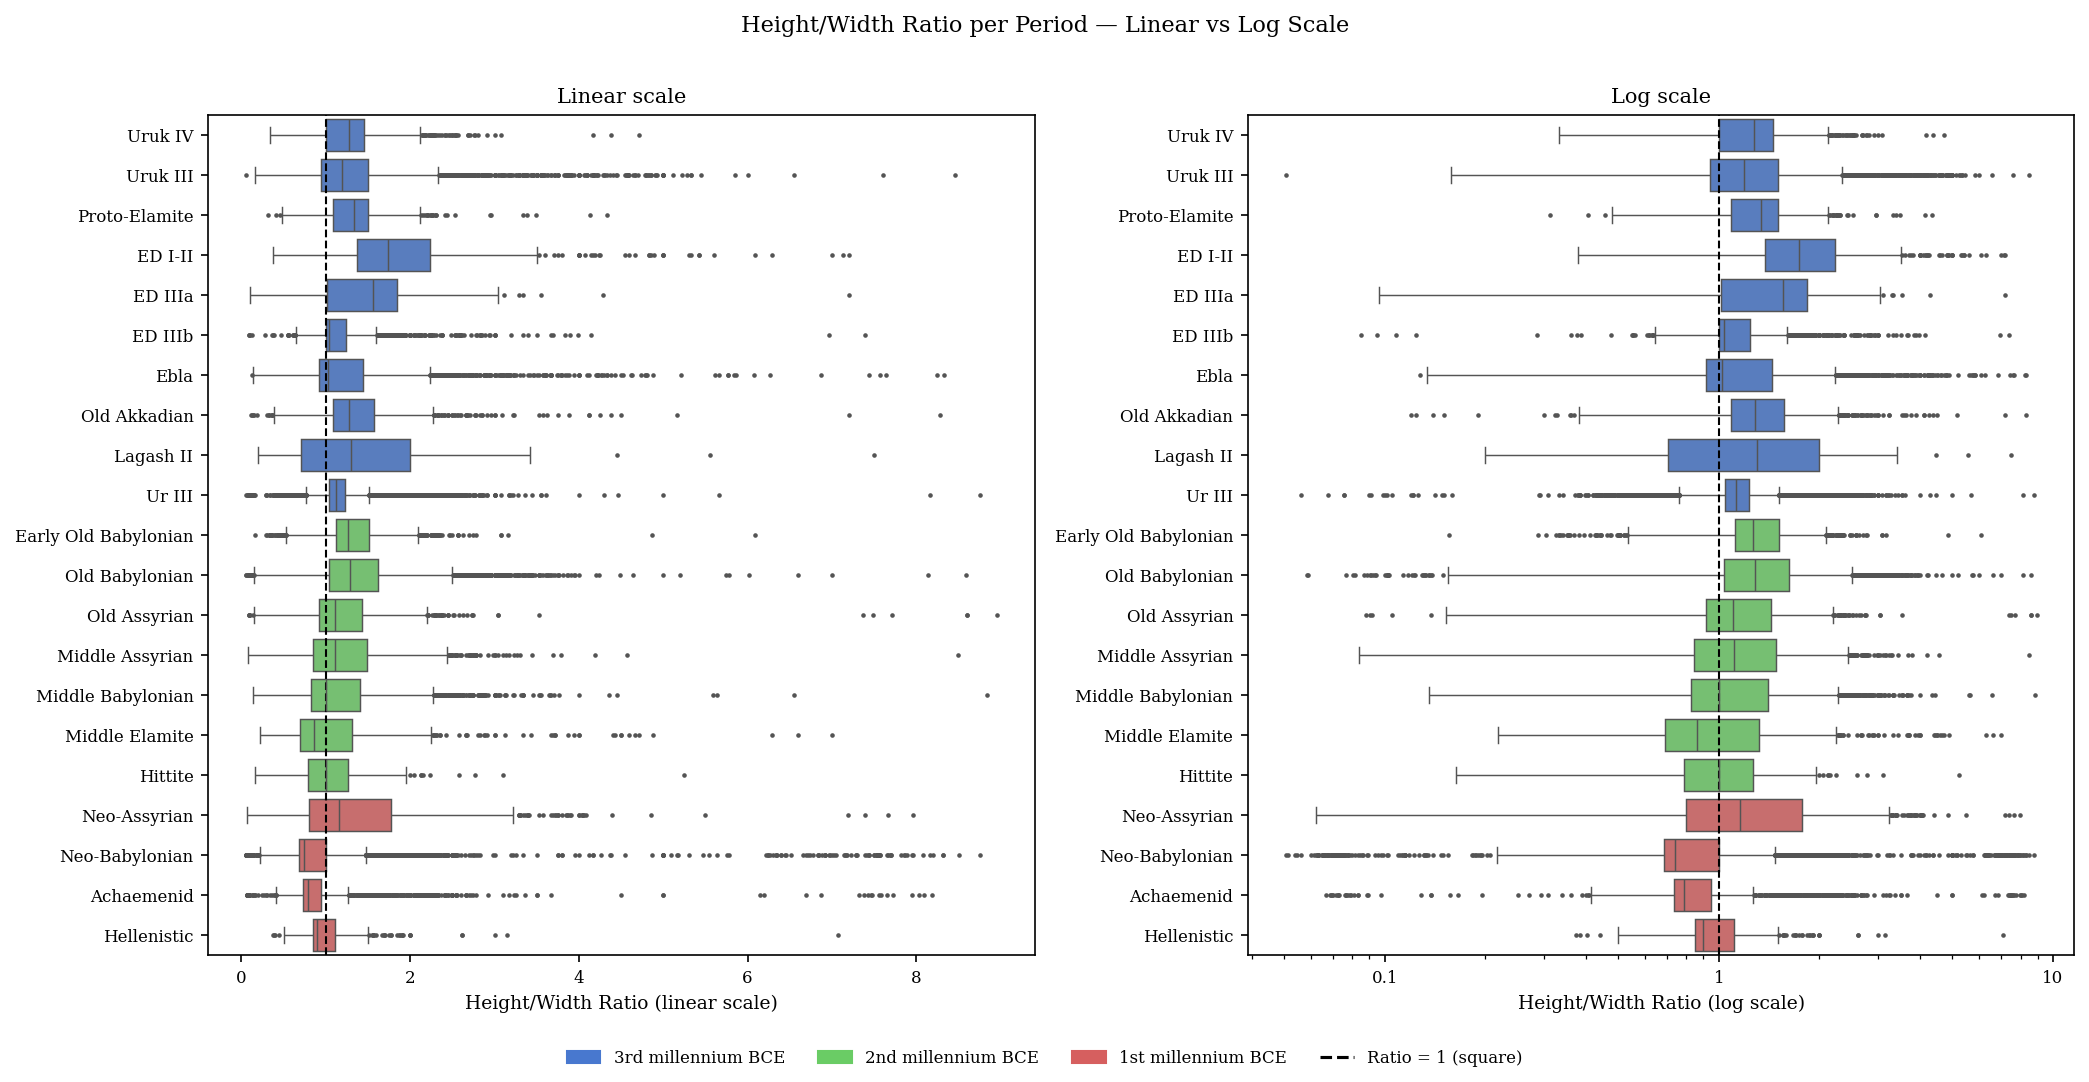

Saved: fig_ratio_linear_vs_log.pdf


In [4]:
PALETTE = {
    '3rd millennium BCE': '#4878CF',
    '2nd millennium BCE': '#6ACC65',
    '1st millennium BCE': '#D65F5F',
}

# Side-by-side comparison: linear vs log
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, xscale in zip(axes, ['linear', 'log']):
    sns.boxplot(
        y='Period_Name', x='hw_ratio', data=ratio_clean,
        order=PERIOD_CHRON_ORDER, hue='millennium',
        hue_order=MILLENNIUM_ORDER, palette=PALETTE,
        fliersize=1.2, linewidth=0.7, dodge=False, ax=ax,
    )
    ax.axvline(1, color='black', ls='--', lw=1)
    if xscale == 'log':
        ax.set_xscale('log')
        ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v,p: f'{v:.2g}'))
    ax.set_xlabel(f'Height/Width Ratio ({xscale} scale)')
    ax.set_ylabel('')
    ax.set_title(f'{xscale.capitalize()} scale')
    ax.get_legend().remove()

handles = [mpatches.Patch(color=v, label=k) for k,v in PALETTE.items()]
handles.append(plt.Line2D([0],[0], color='black', ls='--', label='Ratio = 1 (square)'))
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False)
fig.suptitle('Height/Width Ratio per Period — Linear vs Log Scale', y=1.01)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{FIGURES_DIR}/fig_ratio_linear_vs_log.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_ratio_linear_vs_log.pdf')

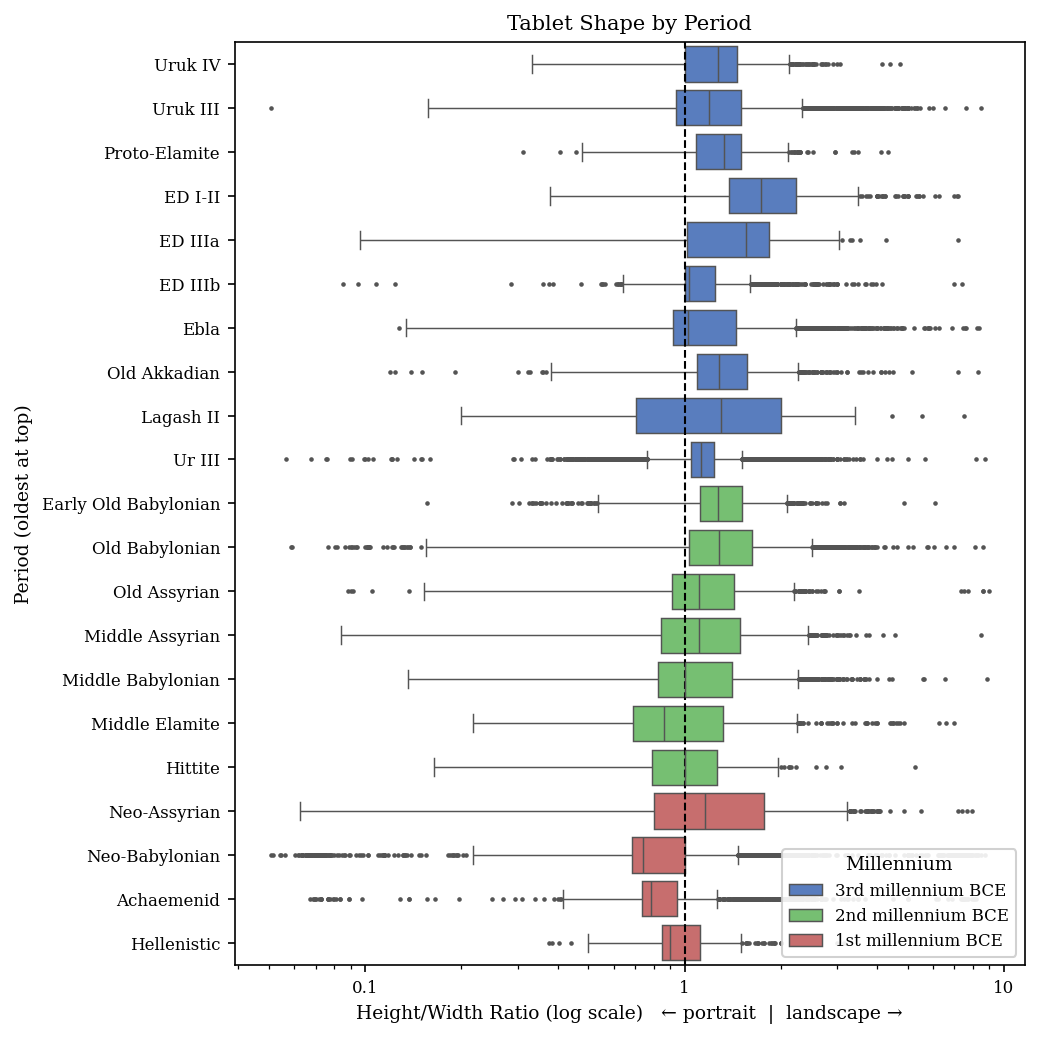

Saved: fig_ratio_by_period_log.pdf


In [5]:
# Publication figure: log-scale box plots by period
fig, ax = plt.subplots(figsize=(7, 7))
sns.boxplot(
    y='Period_Name', x='hw_ratio', data=ratio_clean,
    order=PERIOD_CHRON_ORDER, hue='millennium',
    hue_order=MILLENNIUM_ORDER, palette=PALETTE,
    fliersize=1.2, linewidth=0.7, dodge=False, ax=ax,
)
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v,p: f'{v:.2g}'))
ax.set_xlabel('Height/Width Ratio (log scale)   ← portrait  |  landscape →')
ax.set_ylabel('Period (oldest at top)')
ax.set_title('Tablet Shape by Period')
ax.legend(title='Millennium', loc='lower right', framealpha=0.9)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_ratio_by_period_log.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_ratio_by_period_log.pdf')

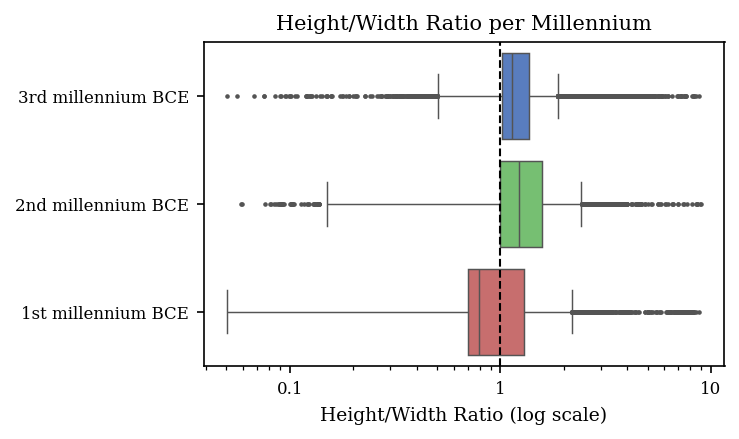

Saved: fig_ratio_by_millennium_log.pdf


In [6]:
# Log-scale box plots by millennium (summary)
fig, ax = plt.subplots(figsize=(5, 3))
sns.boxplot(
    y='millennium', x='hw_ratio', data=ratio_clean,
    order=MILLENNIUM_ORDER, palette=PALETTE,
    fliersize=1.2, linewidth=0.7, ax=ax,
)
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v,p: f'{v:.2g}'))
ax.set_xlabel('Height/Width Ratio (log scale)')
ax.set_ylabel('')
ax.set_title('Height/Width Ratio per Millennium')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_ratio_by_millennium_log.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_ratio_by_millennium_log.pdf')

## 3. Kruskal-Wallis H-test: are period distributions different?

Non-parametric omnibus test (H₀: all period distributions identical).
We use it because ratio distributions are non-normal and sample sizes vary
enormously (n = ~200 to ~19,000).

Effect size η² = (H − k + 1) / (N − k)  
Benchmarks: 0.01 = small, 0.06 = medium, 0.14 = large.

In [7]:
period_groups = [
    ratio_clean.loc[ratio_clean['Period_Name'] == p, 'hw_ratio'].values
    for p in PERIOD_CHRON_ORDER
    if ratio_clean['Period_Name'].eq(p).sum() >= 5
]
periods_tested = [
    p for p in PERIOD_CHRON_ORDER
    if ratio_clean['Period_Name'].eq(p).sum() >= 5
]

H_stat, p_kw = kruskal(*period_groups)
N = sum(len(g) for g in period_groups)
k = len(period_groups)
eta_sq = (H_stat - k + 1) / (N - k)

print('=== Kruskal-Wallis H-test across periods ===')
print(f'Periods tested : {k}')
print(f'N (total)      : {N:,}')
print(f'H statistic    : {H_stat:.2f}')
print(f'p-value        : {p_kw:.2e}')
print(f'η²             : {eta_sq:.4f}')
size_label = 'small' if eta_sq < 0.06 else ('medium' if eta_sq < 0.14 else 'large')
print(f'Effect size    : {size_label}')

=== Kruskal-Wallis H-test across periods ===
Periods tested : 21
N (total)      : 77,512
H statistic    : 9877.47
p-value        : 0.00e+00
η²             : 0.1272
Effect size    : medium


## 4. Spearman rank correlation: is there a monotonic diachronic trend?

In [8]:
period_medians = (
    ratio_clean[ratio_clean['Period_Name'].isin(PERIOD_CHRON_ORDER)]
    .groupby('Period_Name')['hw_ratio']
    .median()
    .reindex(PERIOD_CHRON_ORDER)
    .dropna()
)

chron_ranks = np.arange(1, len(period_medians) + 1)
rho, p_spearman = spearmanr(chron_ranks, period_medians.values)

print('=== Spearman rank correlation: diachronic trend (all genres) ===')
print(f'Periods: {len(period_medians)}')
print(f'ρ       : {rho:.4f}')
print(f'p-value : {p_spearman:.4e}')
print()
print('Period medians:')
for p, m in zip(period_medians.index, period_medians.values):
    print(f'  {p:<30} {m:.3f}  ({"portrait" if m>1 else "landscape"})')

=== Spearman rank correlation: diachronic trend (all genres) ===
Periods: 21
ρ       : -0.7327
p-value : 1.5841e-04

Period medians:
  Uruk IV                        1.276  (portrait)
  Uruk III                       1.192  (portrait)
  Proto-Elamite                  1.333  (portrait)
  ED I-II                        1.733  (portrait)
  ED IIIa                        1.559  (portrait)
  ED IIIb                        1.033  (portrait)
  Ebla                           1.026  (portrait)
  Old Akkadian                   1.280  (portrait)
  Lagash II                      1.305  (portrait)
  Ur III                         1.125  (portrait)
  Early Old Babylonian           1.268  (portrait)
  Old Babylonian                 1.282  (portrait)
  Old Assyrian                   1.106  (portrait)
  Middle Assyrian                1.110  (portrait)
  Middle Babylonian              1.000  (landscape)
  Middle Elamite                 0.863  (landscape)
  Hittite                        1.000  (landscap

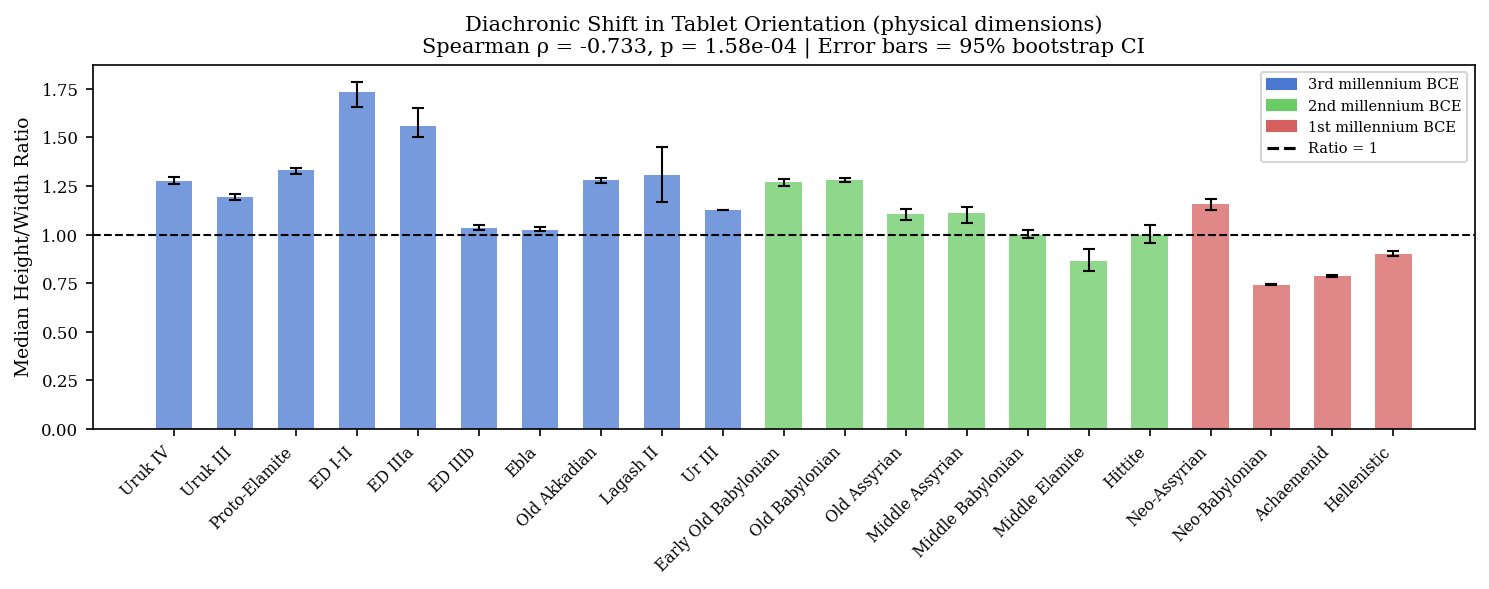

Saved: fig_diachronic_trend.pdf


In [9]:
# Bootstrap 95% CIs on period medians
np.random.seed(42)
N_BOOT = 5000
ci_low, ci_high = [], []
for p in period_medians.index:
    vals = ratio_clean.loc[ratio_clean['Period_Name'] == p, 'hw_ratio'].values
    boot = [np.median(np.random.choice(vals, len(vals), replace=True)) for _ in range(N_BOOT)]
    ci_low.append(np.percentile(boot, 2.5))
    ci_high.append(np.percentile(boot, 97.5))
ci_low, ci_high = np.array(ci_low), np.array(ci_high)

p2m = ratio_clean.drop_duplicates('Period_Name').set_index('Period_Name')['millennium'].to_dict()
colors = [PALETTE.get(p2m.get(p,''), '#888') for p in period_medians.index]

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(period_medians))
ax.bar(x, period_medians.values, color=colors, alpha=0.75, width=0.6, zorder=2)
ax.errorbar(x, period_medians.values,
            yerr=[period_medians.values - ci_low, ci_high - period_medians.values],
            fmt='none', color='black', capsize=3, lw=1, zorder=3)
ax.axhline(1, color='black', ls='--', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(period_medians.index, rotation=45, ha='right', fontsize=7.5)
ax.set_ylabel('Median Height/Width Ratio')
ax.set_title(
    f'Diachronic Shift in Tablet Orientation (physical dimensions)\n'
    f'Spearman ρ = {rho:.3f}, p = {p_spearman:.2e} | '
    f'Error bars = 95% bootstrap CI'
)
handles = [mpatches.Patch(color=v, label=k) for k,v in PALETTE.items()]
handles.append(plt.Line2D([0],[0], color='black', ls='--', label='Ratio = 1'))
ax.legend(handles=handles, loc='upper right', fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_diachronic_trend.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_diachronic_trend.pdf')

## 5. Pairwise Mann-Whitney U between adjacent periods

Bonferroni-corrected. Cliff's δ as effect size.

In [10]:
def cliffs_delta_fast(x, y, max_n=2000, seed=42):
    rng = np.random.default_rng(seed)
    if len(x) > max_n: x = rng.choice(x, max_n, replace=False)
    if len(y) > max_n: y = rng.choice(y, max_n, replace=False)
    x, y = np.array(x), np.array(y)
    return (np.sum(x[:,None] > y[None,:]) - np.sum(x[:,None] < y[None,:])) / (len(x)*len(y))

adj_pairs = list(zip(period_medians.index[:-1], period_medians.index[1:]))
alpha_bonf = 0.05 / len(adj_pairs)

rows = []
for p1, p2 in adj_pairs:
    g1 = ratio_clean.loc[ratio_clean['Period_Name']==p1, 'hw_ratio'].values
    g2 = ratio_clean.loc[ratio_clean['Period_Name']==p2, 'hw_ratio'].values
    if len(g1) < 5 or len(g2) < 5: continue
    _, p_mw = mannwhitneyu(g1, g2, alternative='two-sided')
    delta = cliffs_delta_fast(g1, g2)
    sig  = '***' if p_mw < alpha_bonf else ('*' if p_mw < 0.05 else 'ns')
    esize = 'large' if abs(delta)>=0.43 else ('medium' if abs(delta)>=0.28 else ('small' if abs(delta)>=0.11 else 'negligible'))
    rows.append({'Period 1':p1,'Period 2':p2,'n1':len(g1),'n2':len(g2),
                 'p_MW':round(p_mw,4),"cliffs_delta":round(delta,3),
                 'Bonferroni':sig,'Effect':esize})

adj_df = pd.DataFrame(rows)
print(f'Bonferroni α = {alpha_bonf:.5f}\n')
print(adj_df.to_string(index=False))

Bonferroni α = 0.00250

            Period 1             Period 2    n1    n2   p_MW  cliffs_delta Bonferroni     Effect
             Uruk IV             Uruk III  1808  4985 0.0619         0.039         ns negligible
            Uruk III        Proto-Elamite  4985  1457 0.0000        -0.132        ***      small
       Proto-Elamite              ED I-II  1457   457 0.0000        -0.527        ***      large
             ED I-II              ED IIIa   457   414 0.0000         0.280        ***     medium
             ED IIIa              ED IIIb   414  1895 0.0000         0.361        ***     medium
             ED IIIb                 Ebla  1895  3229 0.0000         0.090        *** negligible
                Ebla         Old Akkadian  3229  3397 0.0000        -0.292        ***     medium
        Old Akkadian            Lagash II  3397   274 0.7484        -0.015         ns negligible
           Lagash II               Ur III   274 22504 0.0002         0.133        ***      small
      

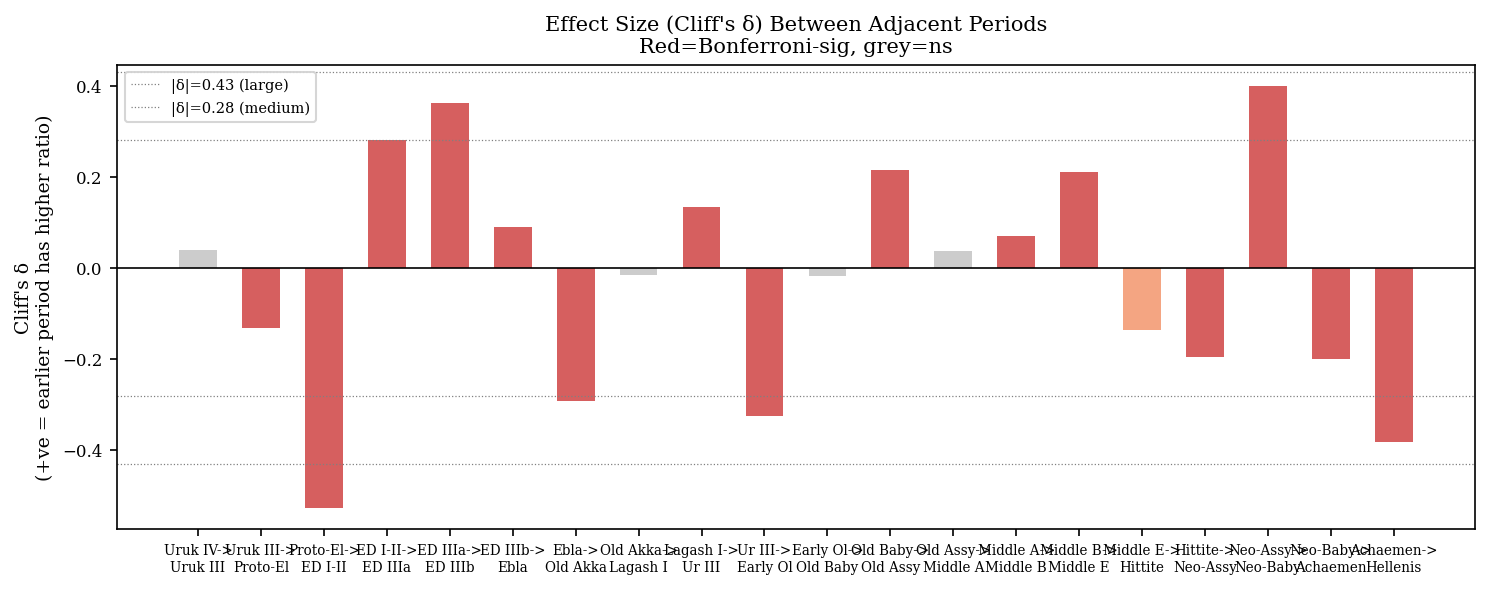

Saved: fig_cliffs_delta_adjacent.pdf


In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
bar_colors = ['#D65F5F' if s=='***' else ('#F4A582' if s=='*' else '#CCCCCC')
              for s in adj_df['Bonferroni']]
x = np.arange(len(adj_df))
ax.bar(x, adj_df['cliffs_delta'], color=bar_colors, width=0.6)
ax.axhline(0, color='black', lw=0.8)
for thresh, label in [(0.43,'large'),(0.28,'medium')]:
    ax.axhline( thresh, color='gray', lw=0.6, ls=':', label=f'|δ|={thresh} ({label})')
    ax.axhline(-thresh, color='gray', lw=0.6, ls=':')
ax.set_xticks(x)
xlabels = [r["Period 1"][:8] + "->\n" + r["Period 2"][:8] for _, r in adj_df.iterrows()]
ax.set_xticklabels(xlabels, fontsize=6.5)
ax.set_ylabel("Cliff's δ\n(+ve = earlier period has higher ratio)")
ax.set_title("Effect Size (Cliff's δ) Between Adjacent Periods\nRed=Bonferroni-sig, grey=ns")
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_cliffs_delta_adjacent.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_cliffs_delta_adjacent.pdf')

## 6. Standardization scale: CV of administrative tablets per period

In [12]:
print('Genre distribution:')
print(ratio_clean['Genre_Name'].value_counts())

Genre distribution:
Genre_Name
Administrative             62781
uncertain                   4137
Legal                       2703
Royal/Monumental            2618
Letter                      2116
Lexical                     1481
Literary                    1004
Other/uncertain              409
Mathematical                 163
Astronomical/Divination      100
Name: count, dtype: int64


In [13]:
def cv_table(df_sub, min_n=10):
    rows = []
    for p in PERIOD_CHRON_ORDER:
        g = df_sub.loc[df_sub['Period_Name']==p, 'hw_ratio'].values
        if len(g) < min_n: continue
        rows.append({'Period':p, 'n':len(g),
                     'Median':round(np.median(g),3),
                     'IQR':round(np.percentile(g,75)-np.percentile(g,25),3),
                     'CV':round(np.std(g,ddof=1)/np.mean(g),3)})
    return pd.DataFrame(rows)

admin = ratio_clean[ratio_clean['Genre_Name']=='Administrative']
cv_all   = cv_table(ratio_clean)
cv_admin = cv_table(admin)

print(f'Administrative tablets: {len(admin):,}\n')
print('--- All genres ---')
print(cv_all.to_string(index=False))
print()
print('--- Administrative genre only ---')
print(cv_admin.to_string(index=False))

Administrative tablets: 62,781

--- All genres ---
              Period     n  Median   IQR    CV
             Uruk IV  1808   1.276 0.455 0.319
            Uruk III  4985   1.192 0.559 0.502
       Proto-Elamite  1457   1.333 0.415 0.279
             ED I-II   457   1.733 0.856 0.519
             ED IIIa   414   1.559 0.828 0.406
             ED IIIb  1895   1.033 0.243 0.363
                Ebla  3229   1.026 0.526 0.569
        Old Akkadian  3397   1.280 0.476 0.321
           Lagash II   274   1.305 1.294 0.605
              Ur III 22504   1.125 0.189 0.251
Early Old Babylonian  2560   1.268 0.391 0.274
      Old Babylonian 15884   1.282 0.589 0.342
        Old Assyrian  1124   1.106 0.515 0.536
     Middle Assyrian  1056   1.110 0.645 0.500
   Middle Babylonian  3023   1.000 0.581 0.460
      Middle Elamite   601   0.863 0.626 0.740
             Hittite   161   1.000 0.474 0.505
        Neo-Assyrian  3379   1.158 0.973 0.539
      Neo-Babylonian  7133   0.741 0.315 0.807
         

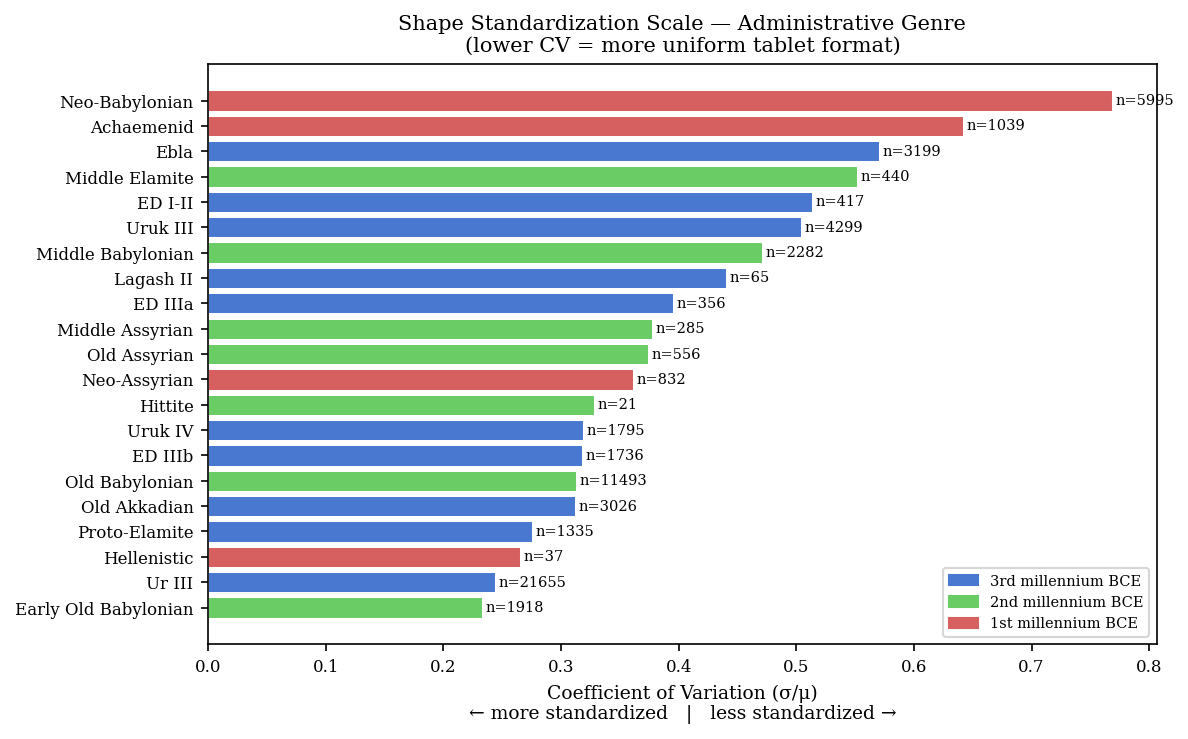

Saved: fig_cv_standardization.pdf


In [14]:
cv_sorted = cv_admin.sort_values('CV')
col = [PALETTE.get(
    ratio_clean.loc[ratio_clean['Period_Name']==p,'millennium'].mode().iloc[0]
    if not ratio_clean.loc[ratio_clean['Period_Name']==p,'millennium'].empty else '', '#888')
    for p in cv_sorted['Period']]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(cv_sorted['Period'], cv_sorted['CV'], color=col, edgecolor='white', lw=0.5)
for bar, n in zip(bars, cv_sorted['n']):
    ax.text(bar.get_width()+0.003, bar.get_y()+bar.get_height()/2,
            f'n={n}', va='center', fontsize=7)
ax.set_xlabel('Coefficient of Variation (σ/μ)\n← more standardized   |   less standardized →')
ax.set_title('Shape Standardization Scale — Administrative Genre\n(lower CV = more uniform tablet format)')
handles = [mpatches.Patch(color=v, label=k) for k,v in PALETTE.items()]
ax.legend(handles=handles, loc='lower right', fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_cv_standardization.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_cv_standardization.pdf')

## 7. Diachronic Spearman within administrative genre

Tests whether the portrait-to-landscape trend is a genre-compositional artefact
(driven by the increasing proportion of first-millennium literary/astronomical
texts) or a genuine shift within a single genre.

In [15]:
admin_meds = (
    admin[admin['Period_Name'].isin(PERIOD_CHRON_ORDER)]
    .groupby('Period_Name')['hw_ratio'].median()
    .reindex(PERIOD_CHRON_ORDER).dropna()
)
rho_a, p_a = spearmanr(np.arange(1,len(admin_meds)+1), admin_meds.values)

# Kruskal-Wallis within administrative
adm_groups = [admin.loc[admin['Period_Name']==p,'hw_ratio'].values
              for p in admin_meds.index if len(admin.loc[admin['Period_Name']==p])>=5]
H_a, p_kw_a = kruskal(*adm_groups)
eta_a = (H_a - len(adm_groups) + 1) / (sum(len(g) for g in adm_groups) - len(adm_groups))

print('=== Administrative genre — diachronic Spearman ===')
print(f'Periods: {len(admin_meds)}')
print(f'ρ = {rho_a:.4f},  p = {p_a:.4e}')
print()
print('=== Administrative genre — Kruskal-Wallis ===')
print(f'H = {H_a:.2f},  p = {p_kw_a:.2e},  η² = {eta_a:.4f}')
print()
print('Administrative medians:')
for p, m in zip(admin_meds.index, admin_meds.values):
    print(f'  {p:<30} {m:.3f}  ({"portrait" if m>1 else "landscape"})')

=== Administrative genre — diachronic Spearman ===
Periods: 21
ρ = -0.4001,  p = 7.2289e-02

=== Administrative genre — Kruskal-Wallis ===
H = 10979.97,  p = 0.00e+00,  η² = 0.1746

Administrative medians:
  Uruk IV                        1.276  (portrait)
  Uruk III                       1.231  (portrait)
  Proto-Elamite                  1.341  (portrait)
  ED I-II                        1.750  (portrait)
  ED IIIa                        1.650  (portrait)
  ED IIIb                        1.031  (portrait)
  Ebla                           1.026  (portrait)
  Old Akkadian                   1.290  (portrait)
  Lagash II                      1.462  (portrait)
  Ur III                         1.125  (portrait)
  Early Old Babylonian           1.250  (portrait)
  Old Babylonian                 1.267  (portrait)
  Old Assyrian                   1.167  (portrait)
  Middle Assyrian                1.923  (portrait)
  Middle Babylonian              0.945  (landscape)
  Middle Elamite            

## 8. Per-period summary statistics table

In [16]:
np.random.seed(42)
summary = []
for p in PERIOD_CHRON_ORDER:
    g = ratio_clean.loc[ratio_clean['Period_Name']==p, 'hw_ratio'].values
    if len(g) < 5: continue
    boot = [np.median(np.random.choice(g,len(g),replace=True)) for _ in range(5000)]
    summary.append({
        'Period': p, 'n': len(g),
        'Median': round(np.median(g),3),
        'CI_95_low':  round(np.percentile(boot,2.5),3),
        'CI_95_high': round(np.percentile(boot,97.5),3),
        'IQR': round(np.percentile(g,75)-np.percentile(g,25),3),
        'CV':  round(np.std(g,ddof=1)/np.mean(g),3),
        'Orientation': 'portrait' if np.median(g)>1 else 'landscape',
    })
summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))
summary_df.to_csv(f'{FIGURES_DIR}/period_summary_stats.csv', index=False)
print('\nSaved: period_summary_stats.csv')

              Period     n  Median  CI_95_low  CI_95_high   IQR    CV Orientation
             Uruk IV  1808   1.276      1.258       1.296 0.455 0.319    portrait
            Uruk III  4985   1.192      1.179       1.208 0.559 0.502    portrait
       Proto-Elamite  1457   1.333      1.313       1.343 0.415 0.279    portrait
             ED I-II   457   1.733      1.657       1.786 0.856 0.519    portrait
             ED IIIa   414   1.559      1.500       1.650 0.828 0.406    portrait
             ED IIIb  1895   1.033      1.025       1.050 0.243 0.363    portrait
                Ebla  3229   1.026      1.016       1.040 0.526 0.569    portrait
        Old Akkadian  3397   1.280      1.267       1.292 0.476 0.321    portrait
           Lagash II   274   1.305      1.170       1.452 1.294 0.605    portrait
              Ur III 22504   1.125      1.125       1.128 0.189 0.251    portrait
Early Old Babylonian  2560   1.268      1.250       1.284 0.391 0.274    portrait
      Old Babylo

## 9. Genre-level box plot

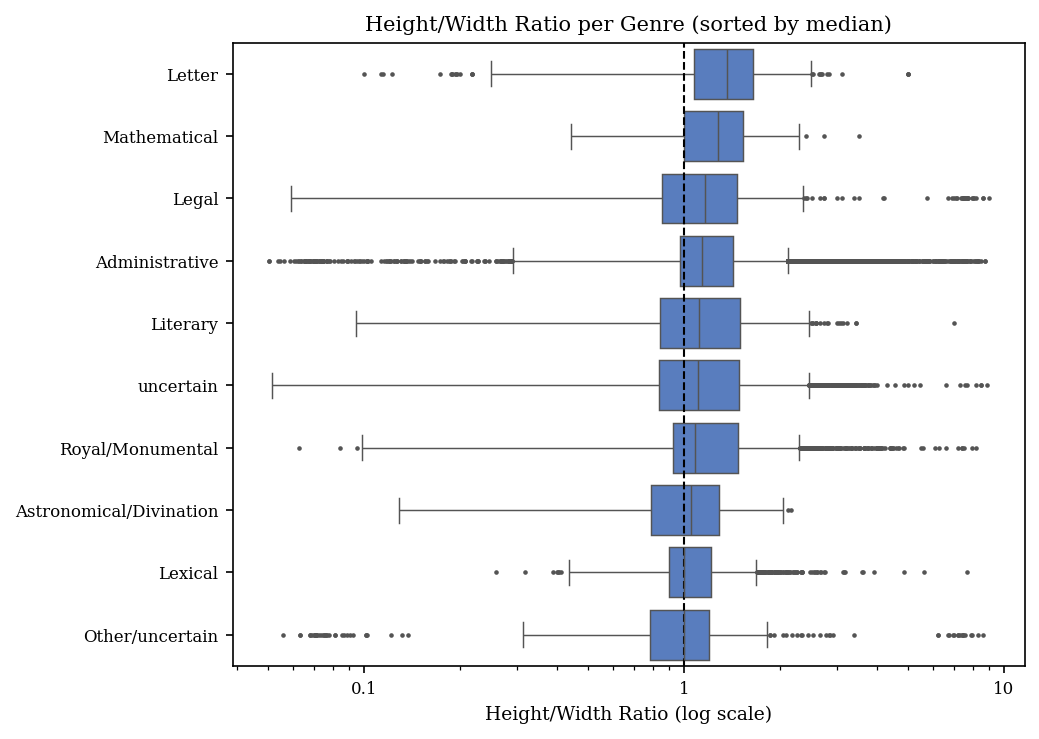

Saved: fig_ratio_by_genre_log.pdf


In [17]:
genre_order = (
    ratio_clean.groupby('Genre_Name')['hw_ratio'].median()
    .sort_values(ascending=False).index.tolist()
)
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(y='Genre_Name', x='hw_ratio', data=ratio_clean,
            order=genre_order, fliersize=1.2, linewidth=0.7,
            color='#4878CF', ax=ax)
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v,p: f'{v:.2g}'))
ax.set_xlabel('Height/Width Ratio (log scale)')
ax.set_ylabel('')
ax.set_title('Height/Width Ratio per Genre (sorted by median)')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_ratio_by_genre_log.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_ratio_by_genre_log.pdf')

## 10. Summary — all results for paper

In [19]:
print('=' * 65)
print('STATISTICAL RESULTS SUMMARY')
print('=' * 65)
print(f'\n1. Kruskal-Wallis (all periods, all genres):')
print(f'   H = {H_stat:.2f},  p = {p_kw:.2e},  eta2 = {eta_sq:.4f}  ({size_label} effect)')
print(f'\n2. Spearman diachronic trend (all genres):')
print(f'   rho = {rho:.4f},  p = {p_spearman:.2e}')
print(f'\n3. Spearman diachronic trend (administrative genre only):')
print(f'   rho = {rho_a:.4f},  p = {p_a:.2e}')
print(f'\n4. Kruskal-Wallis (administrative genre only):')
print(f'   H = {H_a:.2f},  p = {p_kw_a:.2e},  eta2 = {eta_a:.4f}')
print(f'\n5. Adjacent-period pairwise (Bonferroni alpha = {alpha_bonf:.5f}):')
sig_pairs = adj_df[adj_df['Bonferroni']=='***']
ns_pairs  = adj_df[adj_df['Bonferroni']=='ns']
print(f'   Significant breaks: {len(sig_pairs)}')
print(f'   Non-significant (continuity): {len(ns_pairs)}')
for _, r in ns_pairs.iterrows():
    p1, p2, d = r['Period 1'], r['Period 2'], r['cliffs_delta']
    print(f'     {p1} -> {p2}  delta={d:.3f} ns')
print(f'\n6. Standardization (CV, administrative genre):')
if len(cv_admin) > 0:
    hi = cv_admin.loc[cv_admin['CV'].idxmin()]
    lo = cv_admin.loc[cv_admin['CV'].idxmax()]
    print(f'   Most standardized : {hi["Period"]}  CV = {hi["CV"]:.3f}')
    print(f'   Least standardized: {lo["Period"]}  CV = {lo["CV"]:.3f}')
print(f'\nFigures saved to: {FIGURES_DIR}/')
import glob
for fn in sorted(glob.glob(f'{FIGURES_DIR}/*.pdf')):
    print(f'  {os.path.basename(fn)}')


STATISTICAL RESULTS SUMMARY

1. Kruskal-Wallis (all periods, all genres):
   H = 9877.47,  p = 0.00e+00,  eta2 = 0.1272  (medium effect)

2. Spearman diachronic trend (all genres):
   rho = -0.7327,  p = 1.58e-04

3. Spearman diachronic trend (administrative genre only):
   rho = -0.4001,  p = 7.23e-02

4. Kruskal-Wallis (administrative genre only):
   H = 10979.97,  p = 0.00e+00,  eta2 = 0.1746

5. Adjacent-period pairwise (Bonferroni alpha = 0.00250):
   Significant breaks: 15
   Non-significant (continuity): 4
     Uruk IV -> Uruk III  delta=0.039 ns
     Old Akkadian -> Lagash II  delta=-0.015 ns
     Early Old Babylonian -> Old Babylonian  delta=-0.018 ns
     Old Assyrian -> Middle Assyrian  delta=0.038 ns

6. Standardization (CV, administrative genre):
   Most standardized : Early Old Babylonian  CV = 0.233
   Least standardized: Neo-Babylonian  CV = 0.768

Figures saved to: paper/figures/
  fig_cliffs_delta_adjacent.pdf
  fig_cv_standardization.pdf
  fig_diachronic_trend.pdf
  